# COMPUTACIÓN CUÁNTICA - OPTATIVA - GRADOS ING. INFORMÁTICA Y SOFTWARE

# _Notebook_ sobre mediciones en circuitos de un cúbit 

## Entorno de trabajo 

In [1]:
# No olvidar que en "google colab" hay que instalar qiskit
# Instala la última versión disponible en collab (2.1)
try:
    import google.colab
    print("In colab, let's install things...")
    #
    !pip install qiskit==2.1.2 qiskit[visualization] qiskit-aer qiskit-ibm-runtime qiskit-optimization matplotlib numpy scipy sympy pandas
except ImportError:
    print("NOT in colab")

NOT in colab


In [2]:
# Print package versions
import importlib
packages = [
    "qiskit",
    "qiskit_aer",
    "qiskit_ibm_runtime",
    "qiskit_optimization",
]
for pkg in packages:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:25s} : {mod.__version__}")
    except ImportError:
        print("%-25s: %s"%(pkg, "not installed"))


qiskit                    : 2.1.2
qiskit_aer                : 0.18.2
qiskit_ibm_runtime       : not installed
qiskit_optimization      : not installed


## Paquetería

In [3]:
import numpy as np
import scipy.linalg as la
from IPython.display import display, Markdown, Latex, HTML
import matplotlib.pyplot as plt
import copy 

from qiskit.visualization import array_to_latex
from qiskit.visualization import plot_histogram, plot_bloch_multivector, plot_state_qsphere, array_to_latex  
from qiskit.quantum_info import Statevector, schmidt_decomposition
from qiskit.circuit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator

## Utilería  

In [4]:
# Utilería acumulada

# Definimos una función para visualizar el estado y la esfera a la vez
# Permite escalar la(s) esferas(s) con 'inches' pulgadas, si este parámetro
# no se pone, se dibuja al tamaño por defecto
# Si se pone 0, no se dibuja la esfera
def my_display_state_vector(psi, inches=None, prefix=r"|\psi\rangle = "):
    d_latex = psi.draw('latex', prefix=prefix)
    display(d_latex)
    #
    d_bloch = psi.draw('bloch')
    if isinstance(inches, (int,float)):
        if inches > 0:
            d_bloch.set_size_inches(inches, inches, forward=True)
            display(d_bloch)
    else:
        display(d_bloch)

# Función para simular un cirucito dado:
# devuelve esta terna (estado final, cuenta, resultado del job)
def my_get_circuit_state(qcirc_in, shots=1, final_probe=True):
    # Instancia del simulador
    sim = AerSimulator(method = "statevector")
    
    # Hacemos una copia ya que vamos a cambiar el objeto circuito
    qcirc = qcirc_in.copy()
    
    # Ponemos el "probe" para el vector de estado al final
    # del cirucito dado
    # ojo! el circuito no debe de tener un "save_statevector" ya!
    if final_probe:
        qcirc.save_statevector()
    
    # Hacemos una simulación y obtenemos los resultados
    qobj = transpile(qcirc, sim)
    result = sim.run(qobj, shots=shots).result()
    state = result.get_statevector()
    counts_ideal = result.get_counts()
    
    return state, counts_ideal, result

# Función para simular un cirucito dado devuelve el resultado
# de la simulación
def my_circuit_simulation(qcirc, shots=1):
    # Instancia del simulador
    sim = AerSimulator(method = "statevector")
     
    # Hacemos una simulación y obtenemos los resultados


    qobj = transpile(qcirc, backend=sim)
    result = sim.run(qobj, shots=shots).result()
    
    return result

<a id='sec_Notebooks_Circ_1_qubit_1'></a>
## Creación y medición de circuitos de 1 qúbit con Qiskit

Vamos a introducir los objetos Qiskit **Registros**, que pueden ser cuánticos o clásicos.

Básicamente un registro es una _array_ de qubits o bits, respectivamente, y nos sirven para agrupar lógicamente grupos de bits ya sean cuánticos (qubits) o clásicos. 

In [5]:
# Definimos un registro cuántico con un qubit, etiquetado con 'q'
quantum_reg = QuantumRegister(1, 'q') 

# Definimos un registro clásico con un bit, etiquetado con 'c'
classic_reg = ClassicalRegister(1, 'c')

<a id='sec_Notebooks_Circ_1_qubit_1.1'></a>
### Circuito con solo medidor

Creamos un primer circuito. En este solo vamos a poner un medidor. De esta forma vamos a verificar que por defecto Qiskit (y la mayoría de libreas de quantum) inicializan los estados en $| 0 \rangle$

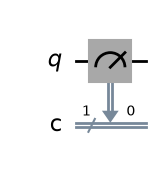

In [6]:
# Creamos el circuito a partir de los registros
circuit = QuantumCircuit(quantum_reg, classic_reg)

# Añadimos el medidor
#   - El primer argumento son los qubits a medir
#   - El segundo argumento son los bits donde volcar el resultado de la medición
circuit.measure(quantum_reg, classic_reg)

# Dibujamos el circuito
circuit.draw(output='mpl', style="iqp") # tipo de figura matplotlib (mpl)

Vamos a simular

In [7]:
# Generamos una instancia del simulador;
# con "method" le especificamos el método de simulación
simulador = AerSimulator(method = 'statevector')

# Transpilamos
circuit_t = transpile(circuit, backend = simulador)

# Ejecutamos la simulación, con un buen número de repeticiones
# (shots = 1000), ya que tenemos un medidor
job = simulador.run(circuit_t, shots = 1000)
result = job.result()

Imprimamos el objeto resultado de la simulación

In [8]:
display(result)

Result(backend_name='aer_simulator_statevector', backend_version='0.18.2', job_id='ee0349a5-d4a0-42d6-9b27-24fb63235825', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x0': 1000}), header={'creg_sizes': [['c', 1]], 'global_phase': 0.0, 'memory_slots': 1, 'n_qubits': 1, 'name': 'circuit-171', 'qreg_sizes': [['q', 1]], 'metadata': {}}, status=DONE, seed_simulator=695099148, metadata={'time_taken': 0.001384219, 'num_bind_params': 1, 'parallel_state_update': 16, 'parallel_shots': 1, 'required_memory_mb': 1, 'input_qubit_map': [[0, 0]], 'method': 'statevector', 'device': 'CPU', 'num_qubits': 1, 'sample_measure_time': 0.000962797, 'active_input_qubits': [0], 'num_clbits': 1, 'remapped_qubits': False, 'runtime_parameter_bind': False, 'max_memory_mb': 15299, 'noise': 'ideal', 'measure_sampling': True, 'batched_shots_optimization': False, 'fusion': {'applied': False, 'max_fused_qubits': 5, 'threshold': 14, 'enabled': True}}, 

Vemos que la salida tiene mucha información. 
Lo más importante es saber cuantas veces se ha medido cada posible medida de nuestro medidor.

In [9]:
counts = result.get_counts()
counts

{'0': 1000}

Vemos que, como era de esperar, las 1000 ejecuciones del circuito nos han dado $| 0 \rangle$

Podemos hacer un histograma con las cuentas. 

Nuevamente, el histograma es una figura de Matplotlib, así que podríamos usar `savefig()`

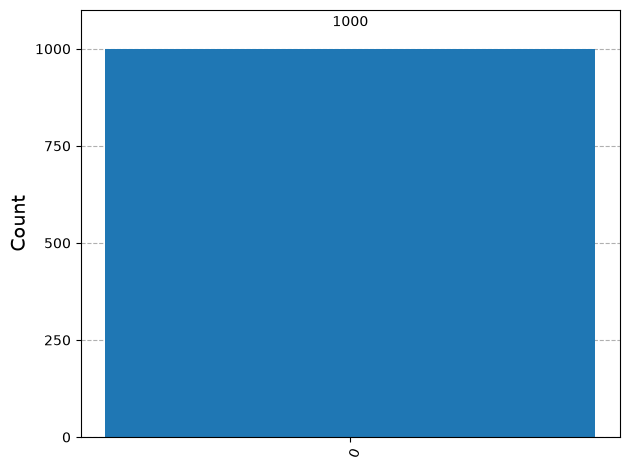

In [10]:
fig = plot_histogram(counts)
#Fig.savefig('/tmp/Fig_circuit_1_hist')
display(fig)

<a id='sec_Notebooks_Circ_1_qubit_1.2'></a>
### Circuito de un qubit con puertas y medidor

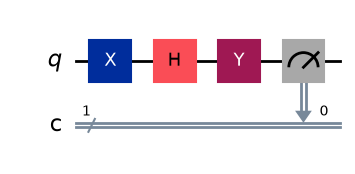

In [11]:
# Creamos el circuito pasandole los registros. 
circuit = QuantumCircuit(quantum_reg, classic_reg)

# Añadimos una puerta X seguida de una H al primer (y único) qúbit
circuit.x(0)
circuit.h(0)
circuit.y(0)

# Añadimos el medidor
circuit.measure(quantum_reg, classic_reg)

# Dibujemos el circuito
display(circuit.draw(output='mpl', style="iqp")) 


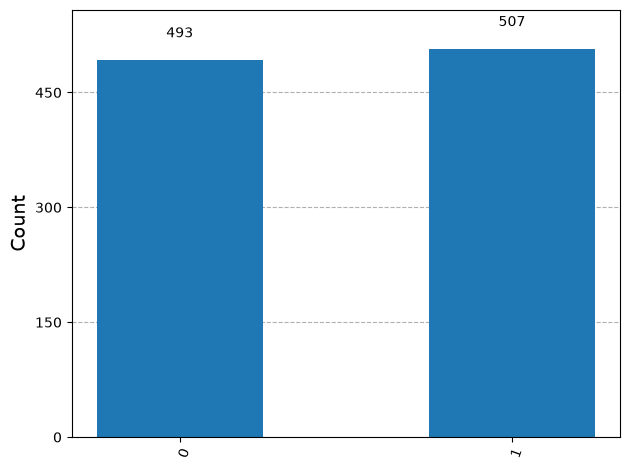

In [12]:
# Usemos nuestra función de utilería que simula y nos da el resultado
result = my_circuit_simulation(circuit, 1000)

# Visualicemos el estado y las probabilidades
counts = result.get_counts()
display(plot_histogram(counts))

In [13]:
# Vamos a definir una función para calcular la distribución de probabilidad

# Toma un histograma en formato diccionario tal como lo devuelve get_counts()
# y lo transforma en otro diccionario con las frecuencias relativas (distribución
# de probabilidad)
def my_get_prob_dist(counts):
    N = 0
    for i in counts.items():
        N += i[1]
    prob = {}
    for i in counts.items():
        prob[i[0]] = float(np.round(i[1]/N, 3))

    # Ordenar el diccionario
    prob = dict(sorted(prob.items()))
    return prob
    

prob_dist = my_get_prob_dist(counts)
print("probability distribution =", prob_dist)

probability distribution = {'0': 0.493, '1': 0.507}


<div style="border:1pt black solid; padding:3pt;">
    
<b>Ejercicio:</b>

Con lápiz y papel, en este circuito, ¿cuál es el estado final del qubit antes del medidor?
    
Observa las frecuencias de aparición de las medidas ¿son aproximadamente las que deben salir?

</div>

In [14]:
# Solución del ejercicio 1: cálculo a mano del estado antes de medir.
# El circuito de la celda anterior parte del estado |0> y aplica, en este orden, X, H e Y.
# Es importante respetar el orden: la primera puerta que actúa es la que está más a la derecha
# en el producto de operadores, por lo que el estado final es Y H X |0>.
#
# 1) X intercambia los estados de la base computacional: X|0> = |1>.
# 2) H|1> = (|0> - |1>)/sqrt(2) = |->.
# 3) Y|0> = i|1> y Y|1> = -i|0>. Por linealidad: 
#       Y (|0> - |1>)/sqrt(2) = (i|1> - (-i|0>))/sqrt(2)
#                                  = i (|0> + |1>)/sqrt(2) = i|+>.
#
# Por tanto, antes del medidor el vector es i[1, 1]/sqrt(2), es decir i|+>.
# El factor global i no cambia ninguna probabilidad observable, así que este estado
# produce las mismas medidas que |+> = (|0>+|1>)/sqrt(2).
# La regla de Born da P(0)=|1/sqrt(2)|^2=1/2 y P(1)=|1/sqrt(2)|^2=1/2.
# Así que el histograma de la celda anterior debe mostrar aproximadamente la mitad
# de ceros y la mitad de unos. No se espera igualdad exacta con un número finito de shots:
# las pequeñas diferencias son fluctuaciones estadísticas de las medidas.

# Comprobación numérica opcional del cálculo analítico con los operadores de Qiskit.
# Statevector.evolve aplica cada puerta al estado y permite comparar el vector obtenido
# con el resultado a mano (salvo diferencias de redondeo o de fase global).
circuito_verificacion = QuantumCircuit(1)
circuito_verificacion.x(0)
circuito_verificacion.h(0)
circuito_verificacion.y(0)
psi_antes_del_medidor = Statevector([1, 0]).evolve(circuito_verificacion)
print("Vector final calculado por Qiskit:", np.round(psi_antes_del_medidor.data, 5))
print("Probabilidades teóricas en la base Z:", np.round(np.abs(psi_antes_del_medidor.data)**2, 5))


Vector final calculado por Qiskit: [0.+0.70711j 0.+0.70711j]
Probabilidades teóricas en la base Z: [0.5 0.5]


<div style="border:1pt black solid; padding:3pt;">
    
<b>Ejercicio:</b>

Añade un medidor al circuito del primer ejercicio del cuadernillo anterior, que no era más que una mera inicialización del qubit.

Comprueba que el histograma está acorde al cuadrado de las amplitudes 0 y 1 en el vector de inicialización.

</div>

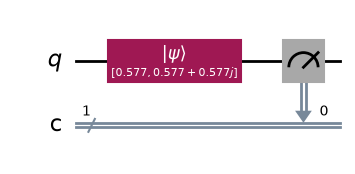

Probabilidades teóricas [P(0), P(1)]: [0.333 0.667]
Conteos observados: {'1': 3335, '0': 1665}
Frecuencias observadas: {'0': 0.333, '1': 0.667}


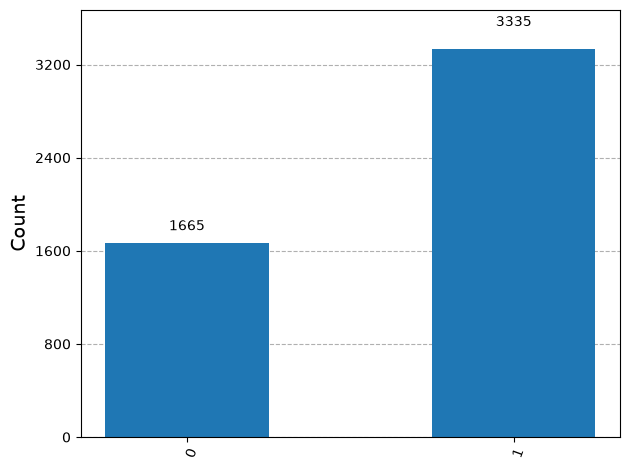

In [15]:
# Solución del ejercicio 2: inicialización de un estado y medida en la base computacional.
# En la práctica 4, el circuito de inicialización recibía un Statevector arbitrario (allí
# se generaba aleatoriamente). Aquí elegimos amplitudes concretas para que la comprobación
# sea reproducible: |psi> = sqrt(1/3)|0> + exp(i*pi/4)*sqrt(2/3)|1>.
# La fase de la segunda amplitud es válida y no afecta a las probabilidades de medir Z;
# los módulos al cuadrado son 1/3 para |0> y 2/3 para |1>.
estado_inicial = Statevector([np.sqrt(1/3), np.exp(1j * np.pi / 4) * np.sqrt(2/3)])

# Creamos un circuito con un cúbit y un bit clásico. initialize prepara el vector indicado
# desde el estado por defecto |0>; measure(q[0], c[0]) guarda el resultado de medir el cúbit.
qc_inicializacion_medida = QuantumCircuit(1, 1)
qc_inicializacion_medida.initialize(estado_inicial, 0)
qc_inicializacion_medida.measure(0, 0)
display(qc_inicializacion_medida.draw(output="mpl", style="iqp"))

# Obtenemos las probabilidades teóricas directamente de las amplitudes del vector.
# La medida estándar de Qiskit distingue |0> y |1> en la base Z, por lo que P(j)=|alpha_j|^2.
probabilidades_teoricas = np.abs(estado_inicial.data) ** 2
print("Probabilidades teóricas [P(0), P(1)]:", np.round(probabilidades_teoricas, 3))

# Ejecutamos muchas repeticiones (shots). El histograma presenta conteos y la función
# my_get_prob_dist los convierte en frecuencias relativas, que aproximan las probabilidades.
resultado_inicializacion = my_circuit_simulation(qc_inicializacion_medida, shots=5000)
cuentas_inicializacion = resultado_inicializacion.get_counts()
print("Conteos observados:", cuentas_inicializacion)
print("Frecuencias observadas:", my_get_prob_dist(cuentas_inicializacion))
display(plot_histogram(cuentas_inicializacion))

# La comparación esperada es aproximadamente (0.333, 0.667). La simulación es aleatoria,
# así que las frecuencias no tienen por qué coincidir exactamente; al aumentar shots,
# normalmente se acercan más a los valores teóricos (ley de los grandes números).


## La moneda cuántica   

Vamos a ver aquí a modo de ejemplo un experimento simple: **la moneda cuántica**.

El resultado de tirar una moneda al aire es una variable aleatoria con dos resultados equiprobables:  cara y cruz.  Es irrelevante si analizamos el resultado cada tirada o cada dos, o tres tiradas. Las frecuencias relativas de caras y cruces, siempre serán próximas a $1/2$. Es decir, podemos tirar la moneda, recogerla sin mirarla, volver a tirar, y las probabilidades no cambian.

Podemos imaginar un experimento similar con un qúbit, donde cara $\to 0$ y cruz $\to 1$ son los resultados posibles de la medida en la base $Z$. Como al tirar la moneda, mientras esta está en el aire podemos pensar que está en ``una superposición equiprobable del cara y cruz'', el hecho de **tirar la moneda** en computación cuántica será aplicar el operador $H$. 

Haciendo esta consideración, podemos ver que no es lo mismo tirar la moneda 1 vez y mirar 


$$
|{0}\rangle~ \stackrel{\rm tirar}{\longrightarrow} ~ H |{0}\rangle= |{+}\rangle ~ \stackrel{\rm medir}{\longrightarrow} ~p(0) = p(1) = 0.5
$$

que tirarla dos veces y mirar

$$
|{0}\rangle~ \stackrel{\rm tirar}{\longrightarrow} ~ H |{0}\rangle~ \stackrel{\rm tirar}{\longrightarrow} H^2|{0}\rangle = |{0}\rangle ~ \stackrel{\rm medir}{\longrightarrow} ~p(0) = 1 ~,~p(1) = 0
$$

El objetivo de este experimento es simplemente ver que ciertas puertas son sus propias inversas y que cuando aplicamos las aplicamos un número par de veces seguidas, es como si no aplicáramos nada. 

Hagamos dos circuitos para hacer dos pruebas. Veamos que pasa si medimos después de la primero $H$ y si no:

In [16]:
classic_reg_2_bits = ClassicalRegister(2)

circuit_coin_1 = QuantumCircuit(quantum_reg, classic_reg_2_bits)
circuit_coin_1.h(0)
circuit_coin_1.measure(quantum_reg, classic_reg_2_bits[0]) # Añadimos una medida intermedia.
circuit_coin_1.h(0)
circuit_coin_1.measure(quantum_reg, classic_reg_2_bits[1])

circuit_coin_2 = QuantumCircuit(quantum_reg, classic_reg)
circuit_coin_2.h(0)
circuit_coin_2.h(0)
circuit_coin_2.measure(quantum_reg, classic_reg)

display(circuit_coin_1.draw(), circuit_coin_2.draw())

┌───┐┌─┐┌───┐┌─┐
   q: ┤ H ├┤M├┤ H ├┤M├
      └───┘└╥┘└───┘└╥┘
c0: 2/══════╩═══════╩═
            0       1

┌───┐┌───┐┌─┐
  q: ┤ H ├┤ H ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0

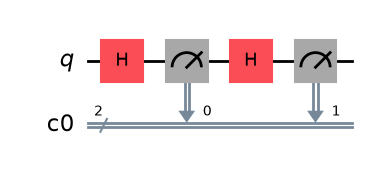

In [17]:
fig_coin_1 = circuit_coin_1.draw(output='mpl', style="iqp") # mpl es de Matplolib
display(fig_coin_1)

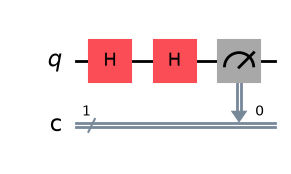

In [18]:
fig_coin_2 = circuit_coin_2.draw(output='mpl', style="iqp") # mpl es de Matplolib
display(fig_coin_2)

In [19]:
# transpilamos

result_coin_1 = my_circuit_simulation(circuit_coin_1, 1000)
result_coin_2 = my_circuit_simulation(circuit_coin_2, 1000)

# Conteo de medidas
counts_coin_1 = result_coin_1.get_counts()
print("Resultado (circuito 1): ", counts_coin_1)
counts_coin_2 = result_coin_2.get_counts()
print("Resultado (circuito 2): ", counts_coin_2)

Resultado (circuito 1):  {'01': 243, '11': 263, '10': 236, '00': 258}
Resultado (circuito 2):  {'0': 1000}


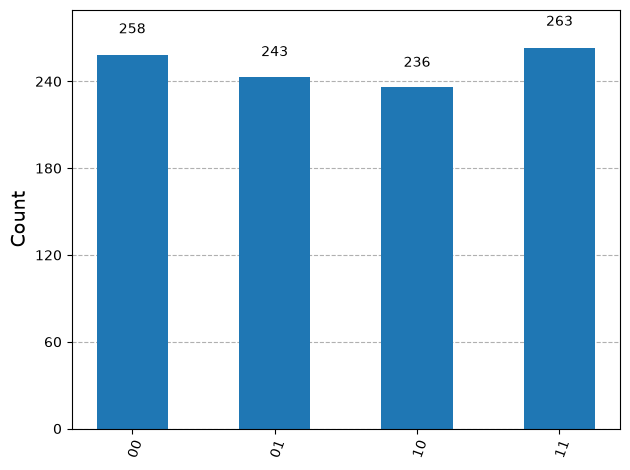

In [20]:
display(plot_histogram(counts_coin_1))

Lo resultados $00$ y$11$ son aquellos en los que hemos medido los mismo en los dos medidores, es decir, en los dos tiradas ha salido cara o cruz. 
En los otros casos, no hemos medido lo mismo, es decir, en una tirada ha salido cara y en la otra cruz.

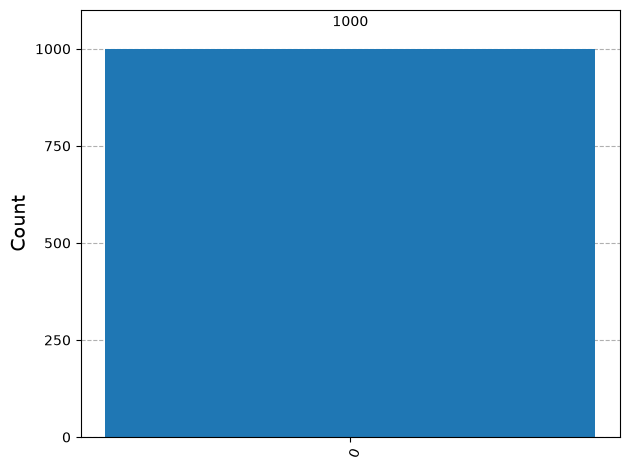

In [21]:
display(plot_histogram(counts_coin_2))

Vemos que **medir altera nuestro resultado**

## Valores esperados  

### Valor esperado de un observable arbitrario (operador hermítico).

Vamos a ver como se mide el valor esperado de un observable arbitrario $A$ en un estado arbitrario $|{\Psi}\rangle$. Estos valores esperados se denotan de la siguiente forma: $\langle Z \rangle_\Psi$. 

Cualquier observable sobre un cúbit cumple $A = A^\dagger$ (es hermítico) con lo que puede expresarse en la base
	\begin{equation} \label{ec_medidas1_expansion_A_en_Paulis}
	A = a I + n_x X + n_y Y  + n_z Z \, .
	\end{equation}
Los coeficientes se obtienen haciendo uso de las relaciones $\frac{1}{2}$ tr$ (\sigma_i \sigma_j) = \delta_{ij}$ y de tr$(\sigma_i)=0$, de las cuales se obtiene
	\begin{align}
	&\boxed{a  = \frac{1}{2} \text{ tr}(A)},        &         &\boxed{n_i = \frac{1}{2} \text{ tr}  (A \sigma_i)},
	\end{align} 
Entonces, podremos obtener el valor esperado de $A$  si somos capaces de medir los valores esperados de $X,$ $Y$ y $Z$.
	\begin{equation}
	\boxed{\langle A\rangle_\Psi = a + n_x \langle X\rangle_\Psi + n_y \langle Y\rangle_\Psi + n_z \langle Z\rangle_\Psi}
	\end{equation}

#### Inicializando estado $| \Psi \rangle $

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

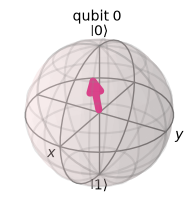

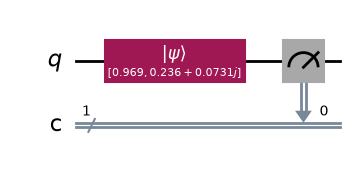

Probabilidades teóricas: p_0= 0.939 , p_1= 0.061
Probabilidades medidas (medidor estándar):  {'0': 0.942, '1': 0.058}


In [22]:
# Vamos a definir un circuito con un valor inicial arbitario
# y vamos a simularlo calculando su distribución de probabilidad

# Para las simulaciones
nshots = 5000

# Inicializamos un estado arbitrario en la esfera de Bloch
theta = 0.5  #rad
phi   = 0.3  #rad
psi_state = [np.cos(theta/2),(np.exp(1j*phi))*np.sin(theta/2)]

# Veamos el vector de estado
Psi = Statevector(psi_state)
display(Psi.draw('latex'))
my_display_state_vector(Psi, 2)

qc = QuantumCircuit(quantum_reg, classic_reg)
qc.initialize(Psi)
qc.measure(quantum_reg, classic_reg)
display(qc.draw('mpl',style="iqp"))

# Simular este mini-circuito, comparar con las probabilidades teóricas en base Z
r = my_circuit_simulation(qc, nshots)
counts = r.get_counts()
print('Probabilidades teóricas: p_0=', np.round(np.abs(psi_state[0])**2,3),', p_1=', np.round(np.abs(psi_state[1])**2,3))
print('Probabilidades medidas (medidor estándar): ', my_get_prob_dist(counts))


#### Midiendo $\langle Z \rangle$

In [23]:
# Circuito
circuit_Z_mean = QuantumCircuit(quantum_reg, classic_reg)
circuit_Z_mean.initialize(Psi,0)
circuit_Z_mean.measure(quantum_reg, classic_reg)

display(circuit_Z_mean.draw())

# Ejecutamos
result_Z_mean = my_circuit_simulation(circuit_Z_mean, nshots)
counts_Z_mean = result_Z_mean.get_counts()
print("Resultado: ", counts_Z_mean)

# Distribución de probabilidad
prob_distr_Z_mean = my_get_prob_dist(counts_Z_mean)
print("probability distribution =", prob_distr_Z_mean)

# Calculamos <Z>
mean_Z = 0

for bits, probs  in prob_distr_Z_mean.items():
    mean_Z += (-1)**(int(bits)) * probs  

print('<Z> =',np.round(mean_Z,5))

┌───────────────────────────────────────┐┌─┐
  q: ┤ Initialize(0.96891,0.23635+0.073113j) ├┤M├
     └───────────────────────────────────────┘└╥┘
c: 1/══════════════════════════════════════════╩═
                                               0

Resultado:  {'1': 327, '0': 4673}
probability distribution = {'0': 0.935, '1': 0.065}
<Z> = 0.87


#### Midiendo $\langle X \rangle$

In [24]:
# Circuito
circuit_X_mean = QuantumCircuit(quantum_reg, classic_reg)
circuit_X_mean.initialize(Psi,0)
circuit_X_mean.h(quantum_reg)
circuit_X_mean.measure(quantum_reg, classic_reg)
circuit_X_mean.h(quantum_reg)

display(circuit_X_mean.draw())

# Ejecutamos
result_X_mean = my_circuit_simulation(circuit_X_mean, nshots)
counts_X_mean = result_X_mean.get_counts()
print("Resultado: ", counts_X_mean)

# Distribución de probabilidad
prob_distr_X_mean = my_get_prob_dist(counts_X_mean)
print("probability distribution =", prob_distr_X_mean)

# Calculamos <X>
mean_X = 0

for bits, probs  in prob_distr_X_mean.items():
    mean_X += (-1)**(int(bits)) * probs  

print('<X> =',np.round(mean_X,5))

┌───────────────────────────────────────┐┌───┐┌─┐┌───┐
  q: ┤ Initialize(0.96891,0.23635+0.073113j) ├┤ H ├┤M├┤ H ├
     └───────────────────────────────────────┘└───┘└╥┘└───┘
c: 1/═══════════════════════════════════════════════╩══════
                                                    0

Resultado:  {'1': 1365, '0': 3635}
probability distribution = {'0': 0.727, '1': 0.273}
<X> = 0.454


#### Midiendo $\langle Y \rangle$

In [25]:
# Circuito
circuit_Y_mean = QuantumCircuit(quantum_reg, classic_reg)
circuit_Y_mean.initialize(Psi,0)
circuit_Y_mean.sdg(quantum_reg)
circuit_Y_mean.h(quantum_reg)
circuit_Y_mean.measure(quantum_reg, classic_reg)
circuit_Y_mean.h(quantum_reg)
circuit_Y_mean.s(quantum_reg)

display(circuit_Y_mean.draw())

# Ejecutamos
result_Y_mean = my_circuit_simulation(circuit_Y_mean, nshots)
counts_Y_mean = result_Y_mean.get_counts()
print("Resultado: ", counts_Y_mean)

# Distribución de probabilidad
prob_distr_Y_mean = my_get_prob_dist(counts_Y_mean)
print("probability distribution =", prob_distr_Y_mean)

# Calculamos <Y>
mean_Y = 0

for bits, probs  in prob_distr_Y_mean.items():
    mean_Y += (-1)**(int(bits)) * probs  

print('<Y> =',np.round(mean_Y,5))

┌───────────────────────────────────────┐┌─────┐┌───┐┌─┐┌───┐┌───┐
  q: ┤ Initialize(0.96891,0.23635+0.073113j) ├┤ Sdg ├┤ H ├┤M├┤ H ├┤ S ├
     └───────────────────────────────────────┘└─────┘└───┘└╥┘└───┘└───┘
c: 1/══════════════════════════════════════════════════════╩═══════════
                                                           0

Resultado:  {'1': 2115, '0': 2885}
probability distribution = {'0': 0.577, '1': 0.423}
<Y> = 0.154


<div style="border:1pt black solid; padding:3pt;">
    
<b>Ejercicio: Reconstrucción cuántica</b>

A partir de los valores promedios medidos anteriores $x=\langle X \rangle$, $y=\langle Y \rangle$, $z=\langle Z \rangle$, se pide:
- Construir el vector 3D cartesiano: $\vec{n}=(x,y,z)$
- Normalizarlo: $\displaystyle \hat{n} = \frac{\vec{n}}{|\vec{n}|}$
- Dibujar estas coordenadas resultantes de $\hat{n}$ sobre la esfera de Bloch, mediante la función que se proporciona en la celda de abajo

Análisis: ¿Qué se observa? ¿Cuál es la explicación del resultado? ¿Influye sobre el mismo el número de _shots_?</div>

In [26]:
# Esta función dibuja un vector 3D con coordenadas euclideas
from qiskit.visualization.bloch import Bloch
def draw_bloch_3d_vector(n, size=(2.5,2.5), show=True):
    # Crear esfera de un tamaño
    bloch = Bloch(figsize=size)
    # Añadir el vector 
    bloch.add_vectors(n)
    if (show):
        bloch.show()
    else:
        return bloch

    
    
# Ejemplo
# n = np.array([1,-2,3])
# n = n/la.norm(n)  # normalizar vector 3D
# draw_bloch_3d_vector(n)

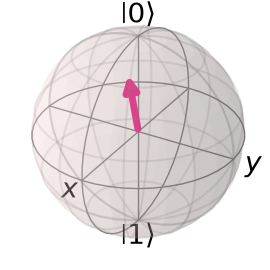

In [27]:
###### Escribe aquí la solución
n = np.array([mean_X, mean_Y, mean_Z])
n = n/la.norm(n)
draw_bloch_3d_vector(n)